# Feature 6 — Performance evaluation
These notebooks use real saved logits, so images, checkpoints, retraining and GPU are unnecessary. Your input is `/content/drive/MyDrive/Features_5_6/real_predictions.csv`.


**Run Feature 5 first.** This notebook reads its saved calibrated test predictions and verifies their hashes. It does not retune anything.

In [1]:
import os
from pathlib import Path
try:
    from google.colab import drive
except ImportError:
    DATA_DIR = Path(os.environ.get('MELANOMA_DATA_DIR', '.')).resolve()
else:
    drive.mount('/content/drive')
    DATA_DIR = Path('/content/drive/MyDrive/MelanomaClassfierProject/Features_5_6')
INPUT = DATA_DIR / 'real_predictions.csv'
assert INPUT.is_file(), f'Put real_predictions.csv in {DATA_DIR}'


Mounted at /content/drive


### 1. Evaluation helpers

In [2]:
import argparse
import hashlib
import json
from pathlib import Path

import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import minimize_scalar
from scipy.special import logsumexp, softmax
from sklearn.metrics import (auc, confusion_matrix, precision_recall_curve,
                             precision_recall_fscore_support, roc_curve)

CLASSES = ['nv', 'mel', 'bkl', 'bcc', 'akiec', 'vasc', 'df']
PRIORITY = ['mel', 'bcc', 'akiec']
ORDER = PRIORITY + [c for c in CLASSES if c not in PRIORITY]
LOGITS = ['logit_' + c for c in CLASSES]
HIGH = [CLASSES.index(c) for c in PRIORITY]
TARGETS = {'mel': .85, 'bcc': .85, 'akiec': .70}


def read_predictions(path):
    """Reject incomplete scores, unknown labels, and duplicate image records."""
    df = pd.read_csv(path)
    required = ['image_id', 'lesion_id', 'dx', 'fold', 'split', 'source', 'model_id'] + LOGITS
    if not set(required) <= set(df.columns):
        raise ValueError('Missing columns: ' + str(sorted(set(required) - set(df.columns))))
    if df[required].isna().any().any() or df.empty:
        raise ValueError('Required fields cannot be empty.')
    if not set(df.dx) <= set(CLASSES) or not set(df.split) <= {'val', 'test'}:
        raise ValueError('Unknown class or split (use val/test).')
    if not np.isfinite(df[LOGITS].to_numpy(float)).all():
        raise ValueError('Logits must be finite numbers.')
    if df.duplicated(['fold', 'split', 'image_id']).any():
        raise ValueError('Duplicate image within a fold/split.')
    if df.groupby('lesion_id').dx.nunique().max() > 1:
        raise ValueError('One lesion has conflicting labels.')
    if set(df.source) not in ({'SIMULATED'}, {'REAL'}):
        raise ValueError('Use one source throughout: SIMULATED or REAL.')
    if df['fold'].nunique() != 5:
        raise ValueError('The primary report requires all five outer folds.')
    for fold, part in df.groupby('fold'):
        if set(part.split) != {'val', 'test'} or part.model_id.nunique() != 1:
            raise ValueError(f'Fold {fold}: need val/test scores from one checkpoint.')
        val = part[part.split == 'val']; test = part[part.split == 'test']
        if set(val.lesion_id) & set(test.lesion_id):
            raise ValueError(f'Fold {fold}: validation/test lesion leakage.')
        if set(val.dx) != set(CLASSES) or set(test.dx) != set(CLASSES):
            raise ValueError(f'Fold {fold}: all seven classes required in val/test.')
    test = df[df.split == 'test']
    if test.image_id.duplicated().any() or test.groupby('lesion_id')['fold'].nunique().max() > 1:
        raise ValueError('Each image/lesion must belong to only one outer test fold.')
    return df


def labels(df):
    return df.dx.map({c: i for i, c in enumerate(CLASSES)}).to_numpy(int)


def fit_temperature(logits, y):
    """Learn one positive temperature on validation by minimizing log loss.

    Temperature rescales confidence; it does not change the top-ranked class.
    Optimize log(T) to prevent an invalid zero/negative temperature.
    """
    def loss(log_t):
        scaled = logits / np.exp(log_t)
        return np.mean(logsumexp(scaled, axis=1) - scaled[np.arange(len(y)), y])
    result = minimize_scalar(loss, bounds=(-4, 4), method='bounded')
    if not result.success:
        raise RuntimeError('Temperature fitting failed.')
    return float(np.exp(result.x))


def choose_threshold(y_binary, scores, min_specificity):
    """Maximize validation recall subject to the requested specificity.

    Ties prefer higher specificity, then the higher (more conservative) cutoff.
    A cutoff just above the largest score permits predicting no positives.
    """
    fpr, tpr, thresholds = roc_curve(y_binary, scores, drop_intermediate=False)
    thresholds[~np.isfinite(thresholds)] = np.nextafter(scores.max(), np.inf)
    eligible = np.flatnonzero(1 - fpr >= min_specificity - 1e-12)
    best = max(eligible, key=lambda i: (tpr[i], -fpr[i], thresholds[i]))
    return float(thresholds[best])


def binary_metrics(actual, predicted):
    tn, fp, fn, tp = confusion_matrix(actual, predicted, labels=[False, True]).ravel()
    return {'recall': float(tp / (tp + fn)) if tp + fn else None,
            'specificity': float(tn / (tn + fp)) if tn + fp else None,
            'precision': float(tp / (tp + fp)) if tp + fp else 0.,
            'tp': int(tp), 'fp': int(fp), 'tn': int(tn), 'fn': int(fn)}


def ece(y, probs, bins=15):
    """Top-label ECE: weighted confidence/accuracy gaps in equal-width bins."""
    confidence = probs.max(axis=1)
    correct = probs.argmax(axis=1) == y
    bucket = np.minimum((confidence * bins).astype(int), bins - 1)
    gap = 0.; rows = []
    for b in range(bins):
        mask = bucket == b
        if mask.any():
            acc = float(correct[mask].mean()); conf = float(confidence[mask].mean())
            gap += mask.mean() * abs(acc - conf)
            rows.append((conf, acc, int(mask.sum())))
    return float(gap), rows


def grouped_recall_ci(y, pred, lesion_ids, iterations=1000, seed=42):
    """Percentile bootstrap over whole lesions, retaining all their images.

    Per-lesion counts make this efficient. Image-level recall is estimated;
    related images are never independently resampled. Absent classes are skipped.
    """
    groups, inverse = np.unique(lesion_ids, return_inverse=True)
    totals = np.zeros((len(groups), 7)); hits = totals.copy()
    np.add.at(totals, (inverse, y), 1)
    np.add.at(hits, (inverse, y), pred == y)
    rng = np.random.default_rng(seed)
    samples = np.full((iterations, 7), np.nan)
    for b in range(iterations):
        draw = rng.integers(0, len(groups), len(groups))
        den = totals[draw].sum(axis=0)
        samples[b] = np.divide(hits[draw].sum(axis=0), den,
                               out=np.full(7, np.nan), where=den > 0)
    return np.nanpercentile(samples, [2.5, 97.5], axis=0)


def binary_recall_ci(truth, predicted, lesion_ids, iterations=2000, seed=42):
    # Resample entire lesions, preserving all images of each sampled lesion.
    groups, inverse = np.unique(lesion_ids, return_inverse=True)
    positives = np.bincount(inverse, weights=np.asarray(truth, int), minlength=len(groups))
    hits = np.bincount(inverse, weights=np.asarray(truth) & np.asarray(predicted), minlength=len(groups))
    rng = np.random.default_rng(seed)
    values = []
    for _ in range(iterations):
        draw = rng.integers(len(groups), size=len(groups))
        denominator = positives[draw].sum()
        if denominator:
            values.append(hits[draw].sum() / denominator)
    return np.percentile(values, [2.5, 97.5]).tolist()
def make_plots(y, probs, raw_probs, out, title):
    """Save raw and row-normalized matrices plus one-vs-rest ROC/PR curves."""
    pred = probs.argmax(axis=1)
    cm = confusion_matrix(y, pred, labels=[CLASSES.index(c) for c in ORDER])
    pd.DataFrame(cm, index=ORDER, columns=ORDER).to_csv(out / 'confusion_counts.csv')
    normalized = cm / cm.sum(axis=1, keepdims=True)
    pd.DataFrame(normalized, index=ORDER, columns=ORDER).to_csv(out / 'confusion_normalized.csv')
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    for ax, matrix, name in zip(axes, [cm, normalized], ['Counts', 'Row proportions']):
        ax.imshow(matrix, cmap='Blues')
        ax.set(xticks=range(7), yticks=range(7), xticklabels=ORDER,
               yticklabels=ORDER, xlabel='Predicted class', ylabel='Actual class', title=name)
        for i in range(7):
            for j in range(7):
                value = str(matrix[i, j]) if name == 'Counts' else f'{matrix[i,j]:.2f}'
                ax.text(j, i, value, ha='center', va='center', fontsize=8,
                        color='white' if matrix[i,j] > matrix.max()*.55 else 'black')
    fig.suptitle(title + ' | Top-1 confusion matrices'); fig.tight_layout()
    fig.savefig(out / 'confusion_matrices.png', dpi=150); plt.close(fig)
    fig, axes = plt.subplots(1, 2, figsize=(12, 5)); curve_rows = []
    for c in ORDER:
        i = CLASSES.index(c); truth = y == i
        fpr, tpr, _ = roc_curve(truth, probs[:, i])
        precision, recall, _ = precision_recall_curve(truth, probs[:, i])
        roc_auc = auc(fpr, tpr); pr_auc = auc(recall, precision)
        axes[0].plot(fpr, tpr, label=f'{c}: {roc_auc:.3f}')
        axes[1].plot(recall, precision, label=f'{c}: {pr_auc:.3f}')
        curve_rows.append({'class': c, 'roc_auc': roc_auc, 'pr_auc_trapezoidal': pr_auc})
    axes[0].plot([0,1], [0,1], '--', color='gray')
    axes[0].set(xlabel='False-positive rate', ylabel='Recall', title='ROC (one vs rest)')
    axes[1].set(xlabel='Recall', ylabel='Precision', title='Precision-recall (one vs rest)')
    for ax in axes: ax.legend(fontsize=8); ax.grid(alpha=.2)
    fig.suptitle(title); fig.tight_layout(); fig.savefig(out / 'curves.png', dpi=150); plt.close(fig)
    pd.DataFrame(curve_rows).to_csv(out / 'curve_auc.csv', index=False)
    fig, ax = plt.subplots(figsize=(6,5)); ax.plot([0,1],[0,1],'--',color='gray')
    for name, p in [('Before', raw_probs), ('After', probs)]:
        value, rows = ece(y,p)
        ax.plot([r[0] for r in rows], [r[1] for r in rows], 'o-', label=f'{name}: ECE={value:.3f}')
    ax.set(xlabel='Mean confidence', ylabel='Observed accuracy', xlim=(0,1), ylim=(0,1), title=title+'\nCalibration')
    ax.legend(); fig.tight_layout(); fig.savefig(out/'calibration.png', dpi=150); plt.close(fig)




### 2. Evaluate all five held-out test folds


In [3]:
F5 = DATA_DIR / 'Feature_5'
OUT = DATA_DIR / 'Feature_6'
OUT.mkdir(parents=True, exist_ok=True)
manifest = json.loads((F5 / 'fold_settings.json').read_text())
assert manifest['input_sha256'] == hashlib.sha256(INPUT.read_bytes()).hexdigest(), 'Rerun Feature 5 for this input.'
assert manifest['oof_sha256'] == hashlib.sha256((F5 / 'out_of_fold_predictions.csv').read_bytes()).hexdigest(), 'Feature 5 output changed.'
assert manifest['class_order'] == CLASSES
original = read_predictions(INPUT)
test = pd.read_csv(F5 / 'out_of_fold_predictions.csv')
y = labels(test)
probs = test[['prob_' + c for c in CLASSES]].to_numpy(float)
raw = test[['raw_prob_' + c for c in CLASSES]].to_numpy(float)
assert np.allclose(probs.sum(axis=1), 1) and np.isfinite(probs).all()
pred = probs.argmax(axis=1)
assert np.array_equal(pred, raw.argmax(axis=1)), 'Temperature should preserve top class.'
ci_bounds = grouped_recall_ci(y, pred, test.lesion_id.to_numpy(), iterations=2000)
precision, recall, f1, support = precision_recall_fscore_support(y, pred, labels=range(7), zero_division=0)
table = pd.DataFrame({'class': CLASSES, 'precision': precision, 'recall': recall,
    'recall_ci_low': ci_bounds[0], 'recall_ci_high': ci_bounds[1], 'f1': f1, 'support': support})
table = table.set_index('class').loc[ORDER].reset_index()
table.to_csv(OUT / 'per_class_metrics.csv', index=False)
risk_truth = np.isin(y, HIGH)
risk_flag = test.high_risk_flag.to_numpy(bool)
risk = binary_metrics(risk_truth, risk_flag)
risk['recall_ci_low'], risk['recall_ci_high'] = binary_recall_ci(risk_truth, risk_flag, test.lesion_id.to_numpy())
# This second statistic describes the pooled test ROC; it is NOT a deployable cutoff.
fpr, tpr, _ = roc_curve(risk_truth, probs[:, HIGH].sum(axis=1), drop_intermediate=False)
descriptive_sensitivity = float(tpr[fpr <= .10 + 1e-12].max())
cm = confusion_matrix(y, pred, labels=range(7))
mel = CLASSES.index('mel'); nv = CLASSES.index('nv')
summary = {'source': 'REAL', 'n_test_images': len(test), 'n_test_lesions': int(test.lesion_id.nunique()),
    'macro_f1': float(f1.mean()), 'weighted_f1': float(np.average(f1, weights=support)),
    'ece_before': ece(y, raw)[0], 'ece_after': ece(y, probs)[0],
    'ece_target': .05, 'meets_ece_target': ece(y, probs)[0] <= .05,
    'mel_to_nv_rate': float(cm[mel, nv] / cm[mel].sum()),
    'nv_to_mel_rate': float(cm[nv, mel] / cm[nv].sum()),
    'high_risk_at_validation_90_specificity': risk,
    'descriptive_test_roc_sensitivity_at_min_90_specificity': descriptive_sensitivity,
    'bootstrap_iterations': 2000, 'input_sha256': manifest['input_sha256']}
(OUT / 'summary.json').write_text(json.dumps(summary, indent=2))
fold_rows = []
for fold, part in test.groupby('fold'):
    fy = labels(part)
    fp = part[['prob_' + c for c in CLASSES]].to_numpy(float)
    fr = part[['raw_prob_' + c for c in CLASSES]].to_numpy(float)
    _, _, ff, fs = precision_recall_fscore_support(fy, fp.argmax(axis=1), labels=range(7), zero_division=0)
    fold_rows.append({'fold': int(fold), 'macro_f1': ff.mean(), 'weighted_f1': np.average(ff,weights=fs),
                     'ece_before': ece(fy, fr)[0], 'ece_after': ece(fy, fp)[0]})
pd.DataFrame(fold_rows).to_csv(OUT / 'metrics_by_fold.csv', index=False)
make_plots(y, probs, raw, OUT, 'Real model: pooled five-fold held-out predictions')
print('Top-1 classification (different from Feature 5 threshold flags):')
print(table.round(4).to_string(index=False))
print(json.dumps(summary, indent=2))


Top-1 classification (different from Feature 5 threshold flags):
class  precision  recall  recall_ci_low  recall_ci_high     f1  support
  mel     0.5298  0.4079         0.3733          0.4444 0.4609     1113
  bcc     0.6380  0.6790         0.6310          0.7242 0.6579      514
akiec     0.5510  0.4954         0.4333          0.5559 0.5217      327
   nv     0.8697  0.9344         0.9270          0.9415 0.9009     6705
  bkl     0.6149  0.5696         0.5365          0.6005 0.5914     1099
 vasc     0.8602  0.5634         0.4730          0.6546 0.6809      142
   df     0.5000  0.0087         0.0000          0.0294 0.0171      115
{
  "source": "REAL",
  "n_test_images": 10015,
  "n_test_lesions": 7470,
  "macro_f1": 0.5472466201124224,
  "weighted_f1": 0.7798887483964138,
  "ece_before": 0.014659955573382875,
  "ece_after": 0.01312110282784414,
  "ece_target": 0.05,
  "meets_ece_target": true,
  "mel_to_nv_rate": 0.42138364779874216,
  "nv_to_mel_rate": 0.031469052945563014,
  "high

### 3. Display saved plots

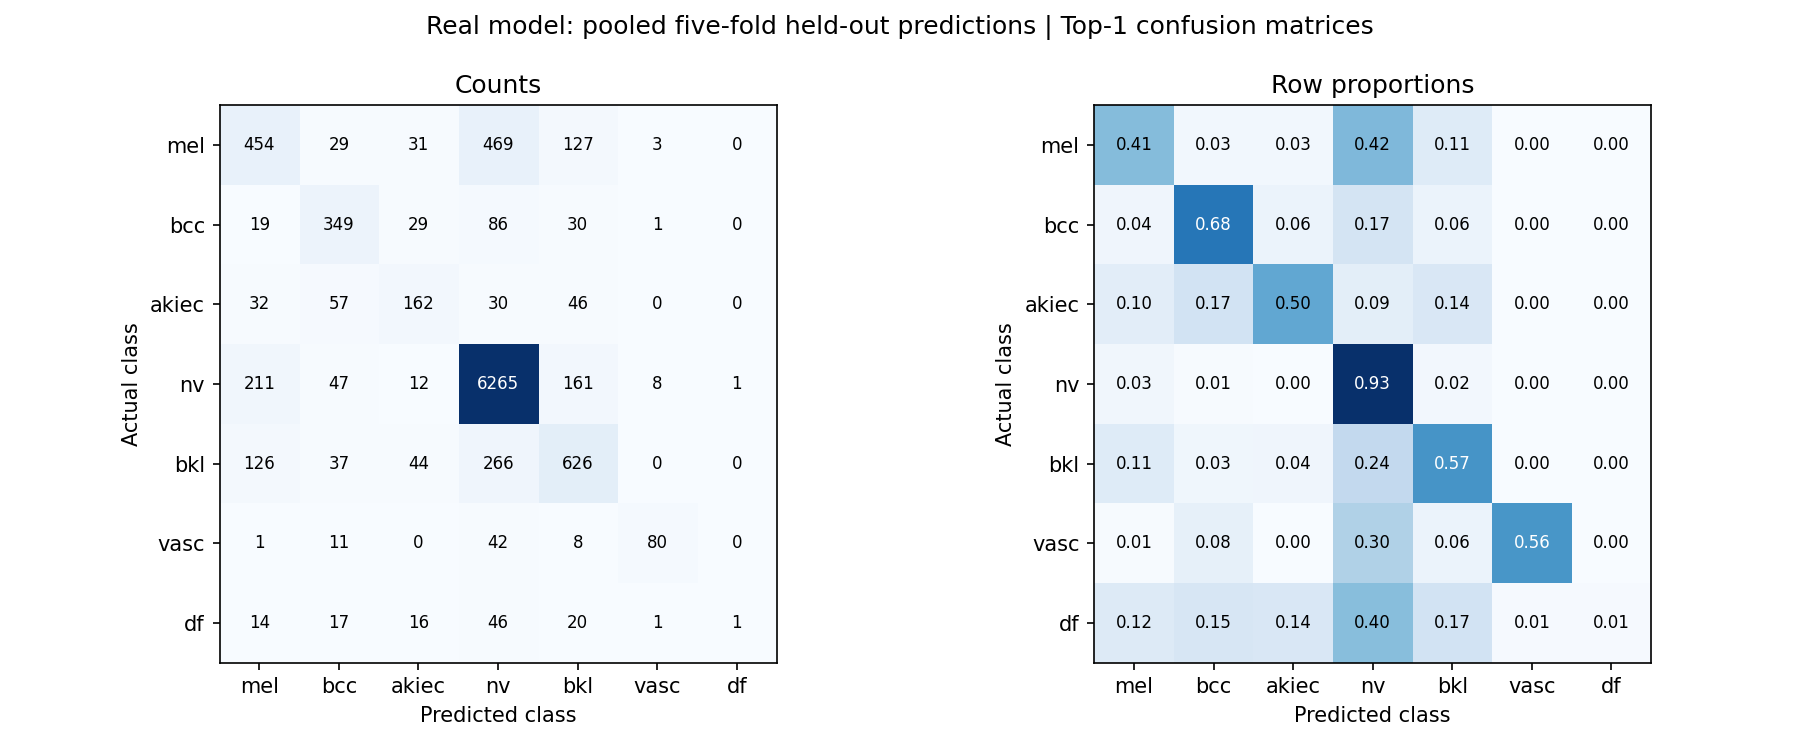

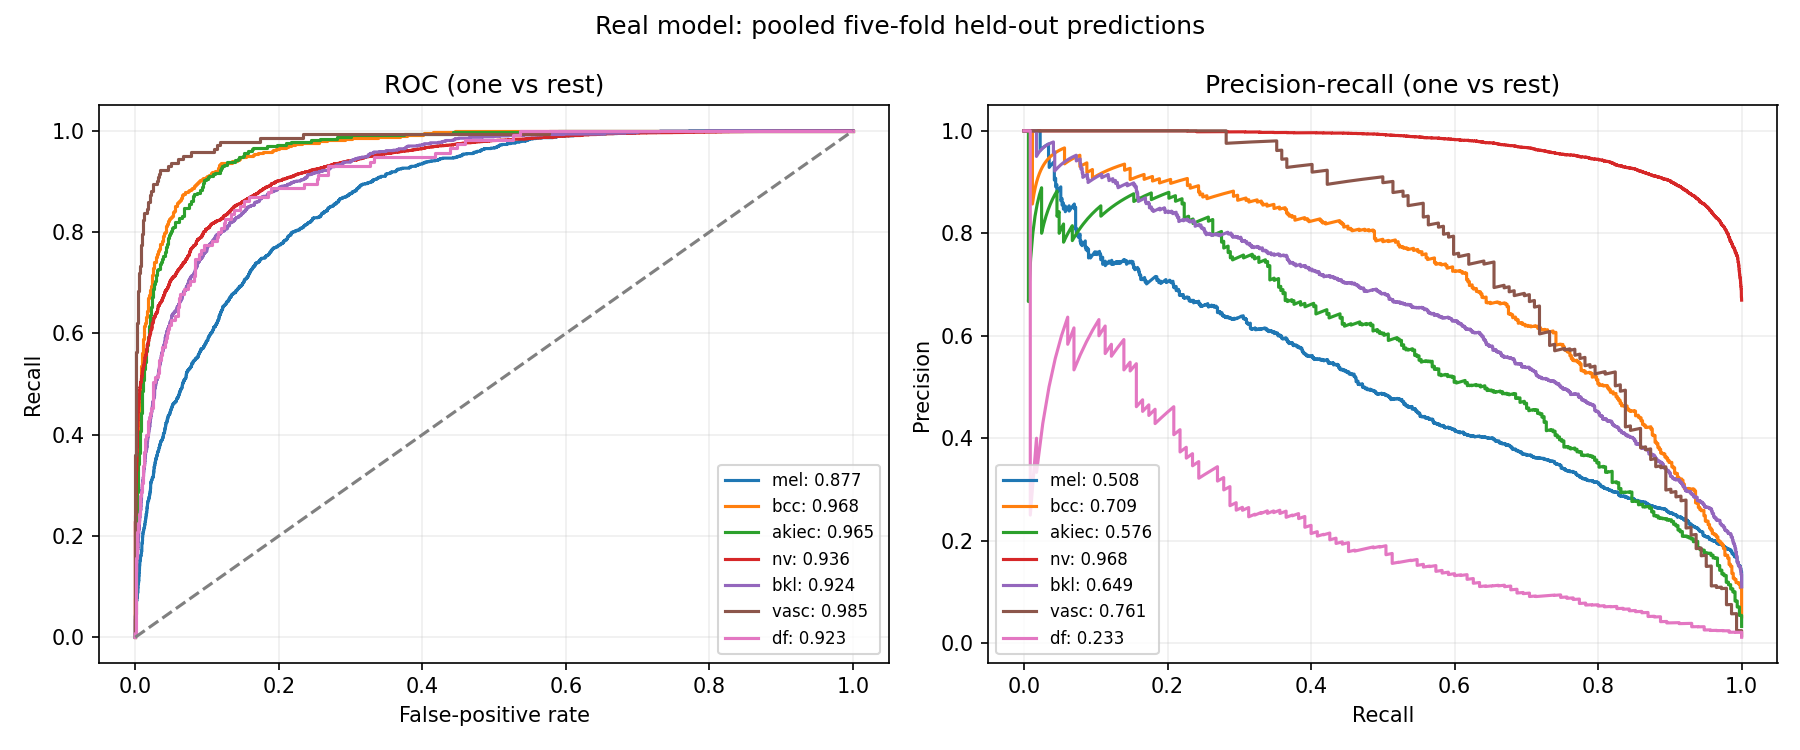

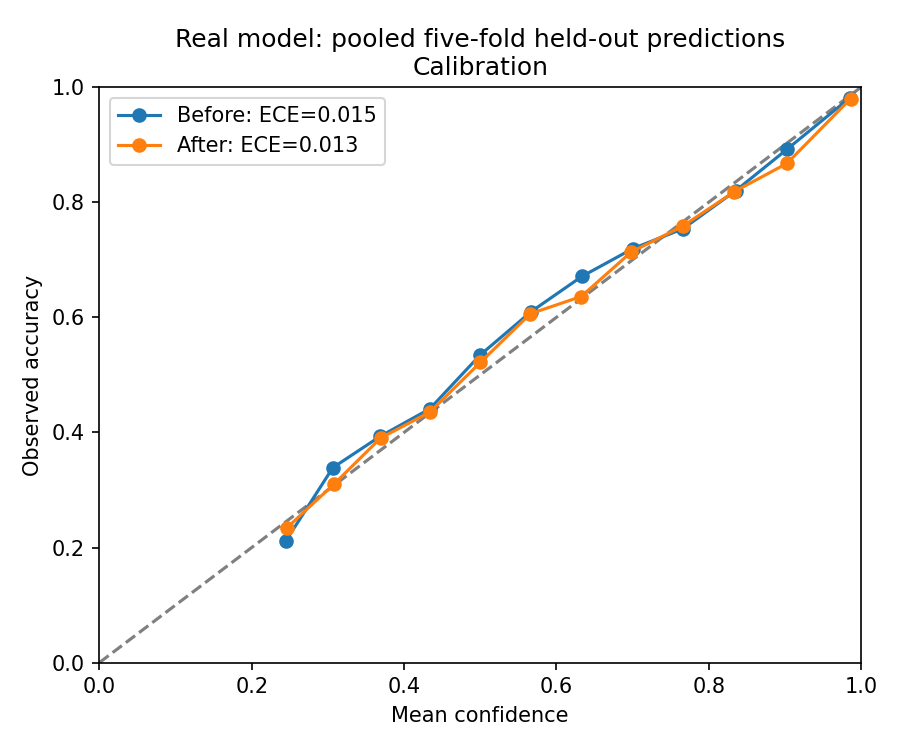

In [4]:
from IPython.display import display, Image
for name in ['confusion_matrices.png', 'curves.png', 'calibration.png']:
    display(Image(filename=str(OUT / name)))